# TuniShop — Machine learning 03. Prédiction du churn

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

## Objectif

Prédire, à chaque fin de trimestre, quels clients actifs **ne recommanderont pas dans les 90 jours** (`churn = 1`), pour cibler les actions de fidélisation.

| Modèle | Rôle |
|---|---|
| Règle « récence » (plus la dernière commande est ancienne, plus le risque est élevé) | **référence** |
| Régression logistique | candidat (simple, interprétable) |
| Forêt aléatoire | candidat |
| Gradient boosting (HistGradientBoosting) | candidat |

**Mesures :** AUC (classement des clients à risque, 0,5 = hasard), précision moyenne, et au seuil choisi : précision, rappel, F1 ; **capture du top 20 %** (part des clients perdus trouvés en ne contactant que les 20 % les plus risqués).

**Validation :** les modèles sont comparés et réglés sur une **validation interne à 2023-2024** (apprentissage sur les photos jusqu'au 31/03/2024, validation sur celles du 30/06 et du 30/09/2024). Le test 2025 n'est utilisé qu'une fois, à la fin.

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.pipeline import make_pipeline

In [2]:
chargement.ouvrir_connexion()

churn = features.lire("ml_churn")
X_COLS, CIBLE = features.colonnes_ml("churn"), "churn"
app, test = churn[churn["periode"] == "apprentissage"], churn[churn["periode"] == "test"]
fin_valid = pd.Timestamp("2024-03-31")
a_fit, a_val = app[app["date_observation"] <= fin_valid], app[app["date_observation"] > fin_valid]
print(f"apprentissage : {len(a_fit):,} photos (validation : {len(a_val):,}) ; test 2025 : {len(test):,}".replace(",", " "))

# 🔗 Contrôle SQL direct : clients actifs au 31/03/2025 (1re photo de test)
d = temporal_split.DATES_OBS_TEST[0]
cle = lambda x: int(pd.Timestamp(x).strftime("%Y%m%d"))
n_sql = chargement.valeur("""
    SELECT COUNT(DISTINCT c.client_sk) FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    WHERE c.client_sk > 0 AND s.statut_commande <> 'paiement_echoue' AND c.date_commande_sk BETWEEN ? AND ?""",
    [cle(d - pd.Timedelta(days=temporal_split.FENETRE_ACTIVITE_J)), cle(d)])
print(f"Clients actifs au {d.date()} — SQL : {int(n_sql)} ; jeu de données : {int((test['date_observation'] == d).sum())}")

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
apprentissage : 14 241 photos (validation : 9 833) ; test 2025 : 19 414
Clients actifs au 2025-03-31 — SQL : 6214 ; jeu de données : 6214


## 1. Comparaison des modèles sur la validation (2024)

In [3]:
candidats = {
    "Régression logistique (C=0,1)": LogisticRegression(C=0.1, max_iter=3000),
    "Régression logistique (C=1)": LogisticRegression(C=1.0, max_iter=3000),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=0),
    "Gradient boosting (lent)": HistGradientBoostingClassifier(learning_rate=0.03, max_iter=400, max_leaf_nodes=15, random_state=0),
    "Gradient boosting (rapide)": HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_leaf_nodes=31, random_state=0),
}
valid = [{"modele": "Règle « récence » (référence)",
          "AUC validation": validation.metriques_classification(a_val[CIBLE], a_val["recence_j"] / a_val["recence_j"].max())["AUC"]}]
for nom, modele in candidats.items():
    pipe = make_pipeline(features.preprocesseur("churn", echelle="logistique" in nom.lower()), modele).fit(a_fit[X_COLS], a_fit[CIBLE])
    valid.append({"modele": nom, "AUC validation": validation.metriques_classification(a_val[CIBLE], pipe.predict_proba(a_val[X_COLS])[:, 1])["AUC"]})
valid = pd.DataFrame(valid).sort_values("AUC validation", ascending=False).reset_index(drop=True)
cfg.exporter_table(valid, "ML03_validation", index=False)
valid

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.ml03_validation                               6 lignes


,modele,AUC validation
0,Gradient boosting (lent),0.822
1,Régression logistique (C=1),0.821
2,"Régression logistique (C=0,1)",0.821
3,Forêt aléatoire,0.820
4,Gradient boosting (rapide),0.817
5,Règle « récence » (référence),0.803


> **Lecture.** Sur la validation (photos du 30/06 et du 30/09/2024), tous les modèles dépassent la règle « récence » (AUC 0,803), mais ils sont **très proches entre eux** (0,817 à 0,822) : le gradient boosting lent arrive en tête, la régression logistique juste derrière.

## 2. Apprentissage final (2023-2024) et test sur 2025

On garde **le meilleur réglage de chaque famille** (logistique, forêt, boosting), on les réapprend sur **tout** 2023-2024, et on fixe le **seuil de décision** sur la validation (celui qui maximise le F1). Puis on mesure tout sur 2025.

In [4]:
familles = {}
for nom in valid["modele"]:
    famille = nom.split(" (")[0]
    if nom in candidats and famille not in familles:
        familles[famille] = nom

finals, resultats, probas = {}, [], {}
ref = test["recence_j"] / test["recence_j"].max()
seuil_ref = validation.meilleur_seuil(a_val[CIBLE], a_val["recence_j"] / test["recence_j"].max())
m_ref = validation.metriques_classification(test[CIBLE], ref, seuil=seuil_ref)
resultats.append({"cas": "churn", "modele": "Règle « récence » (référence)", "role": "référence",
                  "AUC_validation": valid.loc[valid["modele"].str.startswith("Règle"), "AUC validation"].iloc[0], **m_ref})
probas["Règle « récence » (référence)"] = ref.values
for famille, nom in familles.items():
    echelle = famille.startswith("Régression")
    # seuil choisi sur la validation
    pipe_v = make_pipeline(features.preprocesseur("churn", echelle=echelle), candidats[nom]).fit(a_fit[X_COLS], a_fit[CIBLE])
    seuil = validation.meilleur_seuil(a_val[CIBLE], pipe_v.predict_proba(a_val[X_COLS])[:, 1])
    # modèle final sur tout l'apprentissage
    pipe = make_pipeline(features.preprocesseur("churn", echelle=echelle), candidats[nom]).fit(app[X_COLS], app[CIBLE])
    p_test, p_app = pipe.predict_proba(test[X_COLS])[:, 1], pipe.predict_proba(app[X_COLS])[:, 1]
    finals[nom], probas[nom] = pipe, p_test
    resultats.append({"cas": "churn", "modele": nom, "role": "candidat",
                      "AUC_validation": valid.set_index("modele").loc[nom, "AUC validation"],
                      "AUC_apprentissage": validation.metriques_classification(app[CIBLE], p_app)["AUC"],
                      **validation.metriques_classification(test[CIBLE], p_test, seuil=seuil)})
resultats = pd.DataFrame(resultats)
RETENU = resultats[resultats["role"] == "candidat"].sort_values("AUC_validation", ascending=False).iloc[0]["modele"]
resultats["retenu"] = resultats["modele"] == RETENU
cfg.exporter_table(resultats, "ML_metriques_churn", index=False)
resultats.set_index("modele").drop(columns=["cas"]).T

  ✔ ana.ml_metriques_churn                            4 lignes


modele,Règle « récence » (référence),Gradient boosting (lent),Régression logistique (C=1),Forêt aléatoire
role,référence,candidat,candidat,candidat
AUC_validation,0.803,0.822,0.821,0.820
AUC,0.794,0.818,0.814,0.816
precision_moyenne,0.881,0.891,0.887,0.888
precision,0.764,0.743,0.760,0.767
rappel,0.827,0.913,0.875,0.868
F1,0.794,0.819,0.814,0.814
seuil,0.080,0.370,0.420,0.430
taux_reel,0.643,0.643,0.643,0.643
taux_prevu,0.314,0.625,0.630,0.620


> **Lecture.** Sur 2025, le **gradient boosting** obtient une **AUC de 0,818** contre 0,794 pour la règle récence (+2,9 %). Au seuil choisi sur la validation (0,37), il retrouve **91 %** des clients perdus avec une précision de **74 %** (F1 = 0,82). Le taux prévu (62,5 %) est proche du taux réel (64,3 %) : les probabilités sont bien calibrées. Le modèle n'a pas sur-appris (AUC 0,822 en apprentissage, 0,818 en test), contrairement à la forêt aléatoire (0,851 → 0,816).

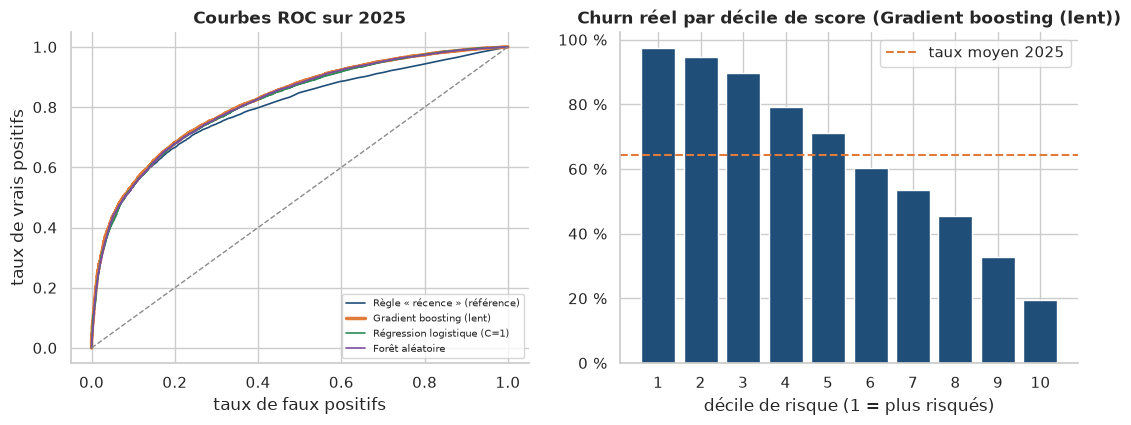

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for i, (nom, p) in enumerate(probas.items()):
    fpr, tpr, _ = roc_curve(test[CIBLE], p)
    axes[0].plot(fpr, tpr, color=cfg.PALETTE[i], lw=2.5 if nom == RETENU else 1.2, label=nom)
axes[0].plot([0, 1], [0, 1], color=cfg.GRIS, ls="--", lw=1)
axes[0].set_title("Courbes ROC sur 2025"); axes[0].set_xlabel("taux de faux positifs"); axes[0].set_ylabel("taux de vrais positifs")
axes[0].legend(fontsize=7)
# Taux de churn réel par décile de score (1 = clients jugés les PLUS à risque, comme dans Power BI)
deciles = pd.qcut(pd.Series(probas[RETENU]).rank(method="first", ascending=False), 10, labels=range(1, 11))
taux = pd.Series(test[CIBLE].values).groupby(deciles.values).mean()
axes[1].bar(taux.index.astype(str), taux.values, color=cfg.BLEU)
axes[1].axhline(test[CIBLE].mean(), color=cfg.ORANGE, ls="--", label="taux moyen 2025")
axes[1].set_title(f"Churn réel par décile de score ({RETENU})"); cfg.format_pourcent(axes[1]); axes[1].set_xlabel("décile de risque (1 = plus risqués)")
axes[1].legend()
montrer("ML03_1_roc_deciles")

> **Lecture.** Les courbes ROC des trois modèles se superposent presque, légèrement au-dessus de la règle récence. Le classement par déciles est net (décile 1 = clients jugés les **plus** à risque, comme dans le tableau de bord Power BI) : **97 %** de churn dans le décile 1, **19 %** dans le décile 10. Les 20 % de clients les plus risqués partent à 96 % : ce sont surtout des clients déjà absents depuis longtemps. **Pour l'action**, les déciles du milieu (4 à 7, 79 à 53 % de churn) sont la cible la plus utile : ce sont des clients encore récupérables.

## 3. Les variables du data mining apportent-elles quelque chose ?

On réapprend le modèle retenu **sans** `segment_rfm`, `score_r`, `score_f`, `score_m` et `cluster`, et on compare son AUC 2025.

In [6]:
dm = ["segment_rfm", "score_r", "score_f", "score_m", "cluster"]
sans = [c for c in X_COLS if c not in dm]
famille = RETENU.split(" (")[0]
pre_sans = features.preprocesseur("churn", echelle=famille.startswith("Régression"))
pre_sans.transformers = [(n_, t_, [c for c in cols if c in sans]) for n_, t_, cols in pre_sans.transformers]
import copy
pipe_sans = make_pipeline(pre_sans, copy.deepcopy(candidats[RETENU])).fit(app[sans], app[CIBLE])
apport = pd.DataFrame({"AUC 2025": {
    "avec les variables du data mining": validation.metriques_classification(test[CIBLE], probas[RETENU])["AUC"],
    "sans les variables du data mining": validation.metriques_classification(test[CIBLE], pipe_sans.predict_proba(test[sans])[:, 1])["AUC"]}})
apport["écart"] = apport["AUC 2025"] - apport["AUC 2025"].iloc[1]
cfg.exporter_table(apport, "ML03_apport_data_mining")
apport

  ✔ ana.ml03_apport_data_mining                       2 lignes


,AUC 2025,écart
avec les variables du data mining,0.818,-0.000
sans les variables du data mining,0.818,0.000


> **Lecture.** Les variables du data mining **n'apportent rien en AUC** (0,8177 avec, 0,8179 sans) : le segment RFM et le groupe k-means résument la récence, la fréquence et le montant, que le modèle a déjà. Ils restent utiles **pour expliquer et agir** (un segment se comprend mieux qu'un score), pas pour prédire mieux.

## 4. Quelles variables comptent ? (importance par permutation)

On mélange une variable à la fois sur 2025 et on mesure la **perte d'AUC** : plus elle est grande, plus le modèle dépend de cette variable.

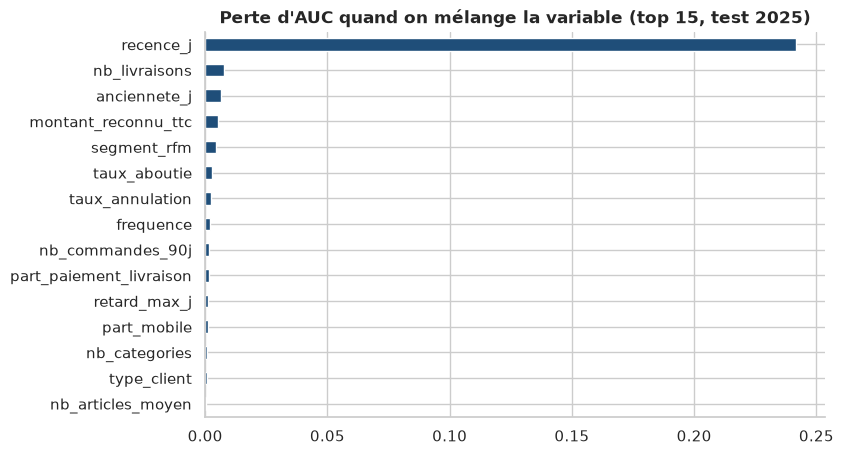

  ✔ ana.ml03_importance                              30 lignes


,perte d'AUC
recence_j,0.242
nb_livraisons,0.008
anciennete_j,0.006
montant_reconnu_ttc,0.005
segment_rfm,0.004
taux_aboutie,0.003
taux_annulation,0.002
frequence,0.002
nb_commandes_90j,0.002
part_paiement_livraison,0.001


In [7]:
echantillon = test.sample(min(6000, len(test)), random_state=0)
imp = permutation_importance(finals[RETENU], echantillon[X_COLS], echantillon[CIBLE], scoring="roc_auc",
                             n_repeats=3, random_state=0, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X_COLS).sort_values(ascending=False)
ax = importance.head(15).iloc[::-1].plot.barh(color=cfg.BLEU, figsize=(8, 5))
ax.set_title("Perte d'AUC quand on mélange la variable (top 15, test 2025)")
montrer("ML03_2_importance")
cfg.exporter_table(importance.to_frame("perte_AUC"), "ML03_importance")
importance.head(15).to_frame("perte d'AUC")

> **Lecture.** La **récence domine** très largement (perte d'AUC de 0,24 quand on la mélange) ; viennent ensuite, loin derrière, le nombre de livraisons reçues, l'ancienneté, le montant et le segment RFM. C'est cohérent avec l'EDA et le RFM : le meilleur signal de départ est le temps écoulé depuis la dernière commande. C'est aussi pourquoi le gain sur la règle récence reste modeste.

## 5. Sauvegarde

In [8]:
joblib.dump({"pipeline": finals[RETENU], "seuil": float(resultats.set_index("modele").loc[RETENU, "seuil"]),
             "variables": X_COLS, "appris_sur": "2023-2024"}, cfg.DOSSIER_MODELES / "churn_modele.joblib")
pred = test[["client_sk", "date_observation", CIBLE]].copy()
pred["proba_churn"] = probas[RETENU]
pred["prediction"] = (pred["proba_churn"] >= resultats.set_index("modele").loc[RETENU, "seuil"]).astype(int)
cfg.exporter_resultat(pred, cfg.DOSSIER_PREDICTIONS / "churn_2025_test.parquet")
print("Modèle : 06_Exports/Modeles/churn_modele.joblib ; prédictions : 06_Exports/Predictions/churn_2025_test.parquet")

  ✔ ana.ml_pred_churn_2025                       19 414 lignes
Modèle : 06_Exports/Modeles/churn_modele.joblib ; prédictions : 06_Exports/Predictions/churn_2025_test.parquet


## 6. Synthèse

> **Lecture.** **Modèle retenu : gradient boosting** (AUC 2025 de 0,818 contre 0,794 pour la règle récence, rappel 91 %, précision 74 %), stable entre la validation et le test et bien calibré. La récence explique l'essentiel ; les variables du data mining n'améliorent pas la prédiction mais servent l'interprétation. Fichiers : `06_Exports/Modeles/churn_modele.joblib` (avec son seuil) et `06_Exports/Predictions/churn_2025_test.parquet`.

In [9]:
chargement.fermer_connexion()

Connexion fermée.
